In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import netcdf_file

In [14]:
root = "/home/ktp9/"
held_suarez_path = "project_pi_mpr49/ktp9/isca_data/held_suarez_default/run0001/atmos_monthly.nc"
hs_file = netcdf_file(root+held_suarez_path, "r")

jup_path = "scratch_pi_mpr49/ktp9/isca_data/giant_planet_test_experiment/run0001/atmos_daily.nc"
jup_file = netcdf_file(root+jup_path, "r")


In [35]:
def get_cdf_var(file, var):
    temp = file.variables[var]
    data = temp[:]*1
    return data

In [39]:
import glob
from scipy.io import netcdf_file
import numpy as np

root = "/home/ktp9/"
pattern = root + "scratch_pi_mpr49/ktp9/isca_data/giant_planet_test_experiment/run*/atmos_daily.nc"

files = sorted(glob.glob(pattern))

temp_list = []
olr_list = []
lon = lat = time = None

for f in files:
    with netcdf_file(f, "r", mmap=False) as nc:
        if lon is None:
            lon  = nc.variables['lon'][:].copy()
            lat  = nc.variables['lat'][:].copy()
        temp_list.append(nc.variables['temp'][:].copy())   # (15, 30, 128, 256)
        olr_list.append(nc.variables['olr'][:].copy())     # (15, 128, 256)
        t = nc.variables['time'][:].copy()
    print(f, temp_list[-1].shape, olr_list[-1].shape, t[0], t[-1])

temp_all = np.concatenate(temp_list, axis=0)   # (N_files*15, 30, 128, 256)
olr_all  = np.concatenate(olr_list,  axis=0)   # (N_files*15, 128, 256)

print("stacked:", temp_all.shape, olr_all.shape)

/home/ktp9/scratch_pi_mpr49/ktp9/isca_data/giant_planet_test_experiment/run0001/atmos_daily.nc (15, 30, 128, 256) (15, 128, 256) 0.5 14.5


KeyError: 'olr'

In [16]:
lon = get_cdf_var(jup_file, 'lon')
lat = get_cdf_var(jup_file, 'lat')
temp = get_cdf_var(jup_file, 'temp')
time = get_cdf_var(jup_file, 'time')

In [19]:
olr = get_cdf_var(jup_file, 'olr')
print(olr.shape)
print(np.unique(olr[-1]))

(15, 128, 256)
[83.79095  83.790955 83.79096  ... 84.11709  84.11723  84.11733 ]


In [6]:
print(lon.shape, lat.shape, time.shape, temp.shape)

(256,) (128,) (15,) (15, 30, 128, 256)


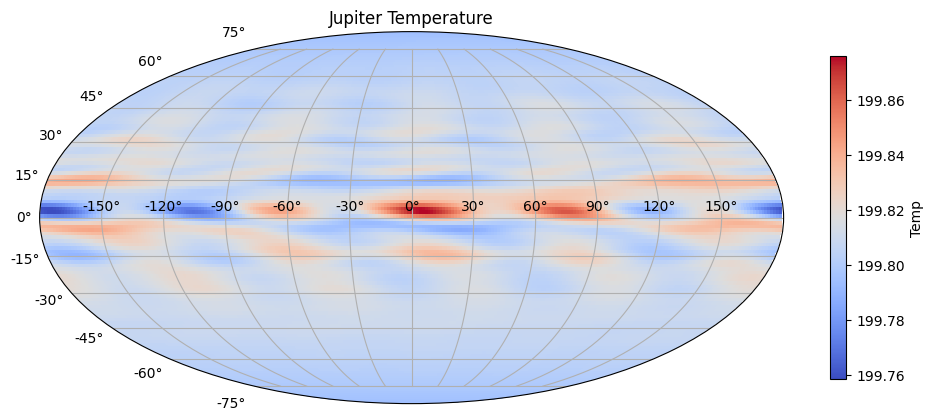

In [20]:
import numpy as np
import matplotlib.pyplot as plt

data = temp.mean(axis=1)[0]   # (64, 128) — (lat, lon)

data = temp[1][0]
label = "Temp"

def plot_molleweide(data, label, title):
    # --- Convert lon from 0..360 to -180..180 by rolling ---
    lon_180 = ((lon + 180) % 360) - 180        # new lon values
    sort_idx = np.argsort(lon_180)             # index that puts them in -180..180 order
    
    lon_shifted = lon_180[sort_idx]
    data_shifted = data[:, sort_idx]
    
    # --- To radians for mollweide ---
    lon_r = np.deg2rad(lon_shifted)
    lat_r = np.deg2rad(lat)
    LON, LAT = np.meshgrid(lon_r, lat_r)
    
    fig = plt.figure(figsize=(12, 6))
    ax = fig.add_subplot(111, projection='mollweide')
    
    pcm = ax.pcolormesh(LON, LAT, data_shifted, cmap='coolwarm', shading='auto')
    plt.colorbar(pcm, ax=ax, orientation='vertical', shrink=0.7, label=label)
    ax.grid(True)

    plt.title(title)

plot_molleweide(data, label, "Jupiter Temperature")
plt.show()

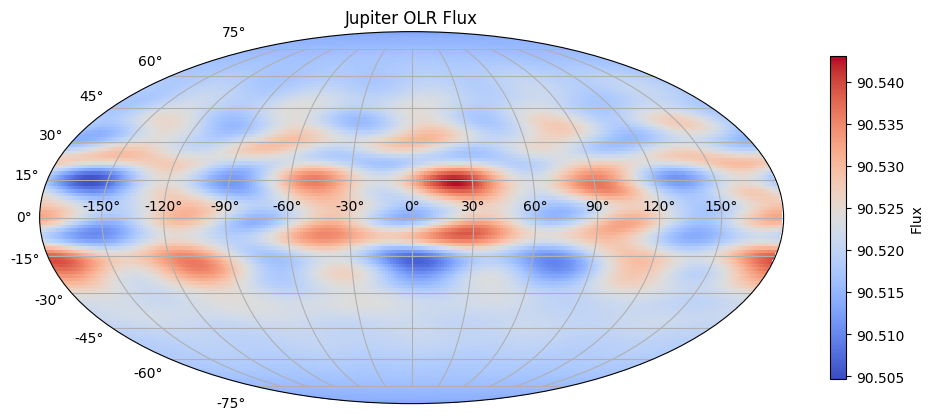

In [26]:
data = olr[0]

plot_molleweide(data, "Flux", "Jupiter OLR Flux")

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

label = "Temp"
data = temp[:, 0, :, :]

def gif_mollweide(data, label, title):
    # --- Precompute lon conversion (same for all frames) ---
    lon_180 = ((lon + 180) % 360) - 180
    sort_idx = np.argsort(lon_180)
    
    lon_shifted = lon_180[sort_idx]
    lon_r = np.deg2rad(lon_shifted)
    lat_r = np.deg2rad(lat)
    LON, LAT = np.meshgrid(lon_r, lat_r)
    
    # --- Set up figure ---
    fig = plt.figure(figsize=(12, 6))
    ax = fig.add_subplot(111, projection='mollweide')
    
    # Use first frame to establish color limits (or set manually if you prefer)
    first_data = data[0][:, sort_idx]
    vmin = np.nanmin(first_data)
    vmax = np.nanmax(first_data)
    # Optional: use global min/max across all frames so the colorbar is stable:
    all_data = np.array([temp[i][0][:, sort_idx] for i in range(len(temp))])
    vmin, vmax = np.nanmin(all_data), np.nanmax(all_data)
    
    pcm = ax.pcolormesh(LON, LAT, first_data, cmap='coolwarm', shading='auto',
                        vmin=vmin, vmax=vmax)
    cbar = plt.colorbar(pcm, ax=ax, orientation='vertical', shrink=0.7, label=label)
    ax.grid(True)
    axtitle = ax.set_title(title + " — frame 0")
    
    def update(i):
        data_shifted = data[i][:, sort_idx]
        pcm.set_array(data_shifted.ravel())
        pcm.set_clim(vmin=np.nanmin(data_shifted), vmax=np.nanmax(data_shifted))
        cbar.update_normal(pcm)
        axtitle.set_text(title + f" — frame {i}")
        return pcm, title
    
    anim = FuncAnimation(fig, update, frames=len(data), interval=100, blit=False)
    
    # Save as GIF
    anim.save("jupiter_" + title + ".gif", writer=PillowWriter(fps=1))
    plt.close(fig)

gif_mollweide(data, label, "temp")

In [32]:
data = olr
label = "Flux"
gif_mollweide(data, label, title = "olr")

[175.95425 161.3585  162.23685 167.63177 173.9639  179.97054 185.19154
 189.48868 192.87344 195.43155 197.2845  198.56654 199.40935 199.9315
 200.23218 200.38861 200.45726 200.47731 200.47568 200.47308 200.49089
 200.55997 200.73244 201.09756 201.80257 203.05836 204.98796 207.14941
 209.27437 211.3467 ]


Text(0.5, 1.0, 'Jupiter Time, Space Averaged T-P')

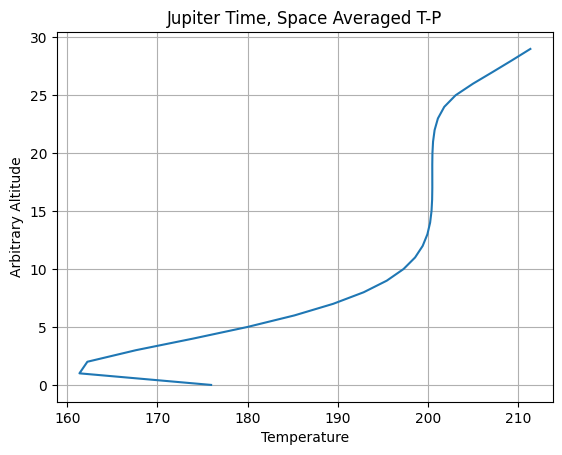

In [9]:
non_pressure_dims = (temp.shape[0] * temp.shape[2] * temp.shape[3])
t_of_p = temp.sum(axis=0).sum(axis=1).sum(axis=1) / non_pressure_dims
print(t_of_p)
# --> low presure at [0], higher at [-1]

plt.plot(t_of_p, np.arange(0, len(t_of_p), 1))
plt.ylabel("Arbitrary Altitude")
plt.xlabel("Temperature")
plt.grid()
plt.title("Jupiter Time, Space Averaged T-P")

[194.18729 194.17105 194.15495 194.13893 194.12288 194.1069  194.09102
 194.07526 194.05963 194.04414 194.02881 194.0137  193.99883 193.98436
 193.97087]


Text(0.5, 1.0, 'Jupiter Pressure, Space Averaged Temp')

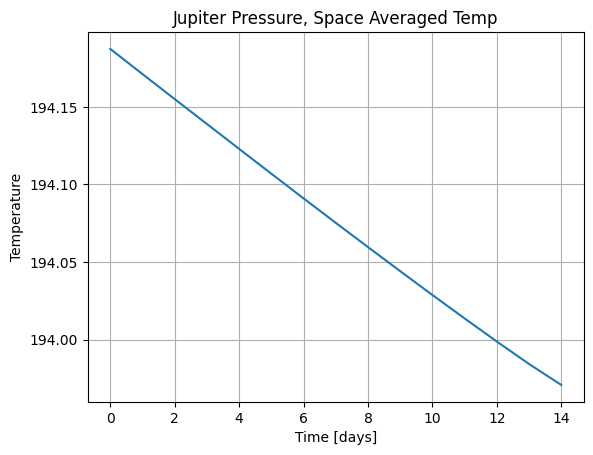

In [10]:
non_time_dims = (temp.shape[1] * temp.shape[2] * temp.shape[3])
T_of_t = temp.sum(axis=1).sum(axis=1).sum(axis=1) / non_time_dims
print(T_of_t)
# --> low presure at [0], higher at [-1]

plt.plot(T_of_t)
plt.xlabel("Time [days]")
plt.ylabel("Temperature")
plt.grid()
plt.title("Jupiter Pressure, Space Averaged Temp")

[90.52002  90.003296 89.49696  88.99817  88.506744 88.02249  87.54526
 87.07484  86.611115 86.15391  85.703064 85.258446 84.81992  84.38733
 83.96275 ]


Text(0.5, 1.0, 'Jupiter Space Averaged OLR')

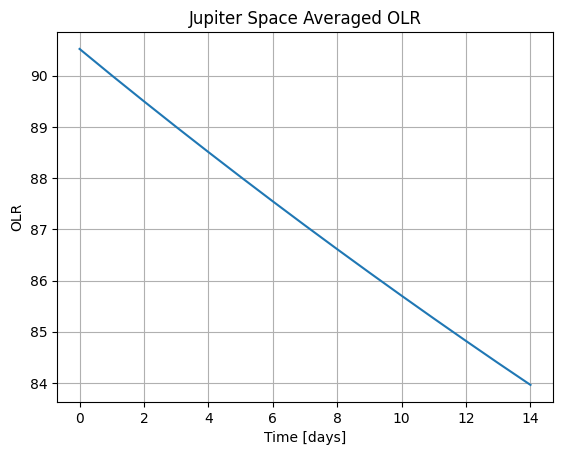

In [33]:
non_time_dims = (olr.shape[1] * olr.shape[2])
T_of_t = olr.sum(axis=1).sum(axis=1) / non_time_dims
print(T_of_t)
# --> low presure at [0], higher at [-1]

plt.plot(T_of_t)
plt.xlabel("Time [days]")
plt.ylabel("OLR")
plt.grid()
plt.title("Jupiter Space Averaged OLR")